## Import Packages

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras._tf_keras.keras import layers
from keras._tf_keras.keras.models import Sequential
from keras._tf_keras.keras.layers import Dense,Flatten,Dropout,BatchNormalization
from keras._tf_keras.keras.losses import SparseCategoricalCrossentropy
from keras._tf_keras.keras.callbacks import EarlyStopping

## Set Constant Values

In [3]:
BATCH_SIZE = 32
IMAGE_SIZE = 224
CHANNELS = 3

## Download or load the dataset 

In [4]:
training = "Tomato/train/"
testing = "Tomato/test/"

## Image Preprocessing

### Create Dataset for train,test,validation

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
  training,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 14523 files belonging to 10 classes.
Using 11619 files for training.


In [6]:
test_ds = tf.keras.utils.image_dataset_from_directory(
  testing,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 3637 files belonging to 10 classes.
Using 2910 files for training.


In [7]:
val_ds = tf.keras.utils.image_dataset_from_directory(
  training,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 14523 files belonging to 10 classes.
Using 2904 files for validation.


In [8]:
class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)

['Tomato___bacterial_spot', 'Tomato___early_blight', 'Tomato___healthy', 'Tomato___late_blight', 'Tomato___leaf_curl', 'Tomato___leaf_mold', 'Tomato___mosaic_virus', 'Tomato___septoria_leaf_spot', 'Tomato___spider_mites', 'Tomato___target_spot']


## Visualize the data

In [9]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 224, 224, 3)
(32,)


## Configure the dataset for performance

In [10]:
trian_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

## Standardize the data

In [11]:
normalization_layer = layers.Rescaling(1./255)

In [12]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.0017006674 0.97380495


## Resize and Rescale

In [13]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(0.1 / 256)
])

## Data Augmentation

In [14]:
data_augmentation  = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.2)
])

In [15]:
train_ds = train_ds.map(
    lambda x,y: (data_augmentation(x, training=True),y),
).prefetch(buffer_size = tf.data.AUTOTUNE)

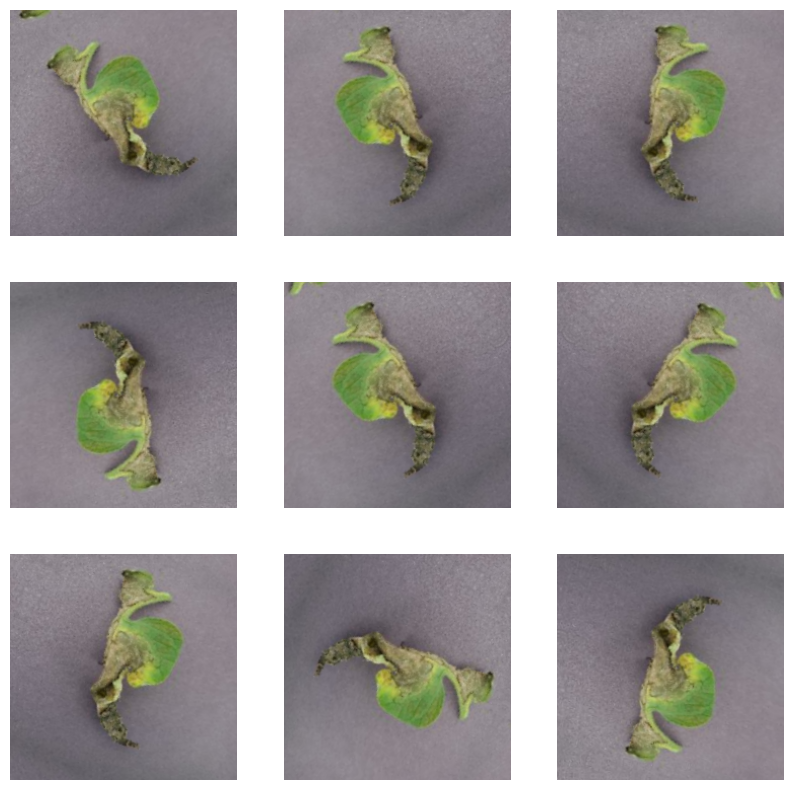

In [16]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

Define the EarlyStopping callback

In [17]:
early_stopping = EarlyStopping(
    monitor='val_loss',  # or 'val_accuracy' depending on your goal
    patience=3,          # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True,  # Restore model weights from the epoch with the best value of the monitored quantity
    verbose=1
)

# CNN Model Implementation

Model Layering

In [18]:
model = Sequential([
  data_augmentation,
  layers.Rescaling(1./255),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(128, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Dropout(0.2),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

Compile the model

In [19]:
model.compile(
    optimizer='adam',
    loss= "sparse_categorical_crossentropy",
    metrics=['accuracy']
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,310,122 (12.63 MB)

 Trainable params: 3,310,122 (12.63 MB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [20]:
epochs = 30
history = model.fit(
  train_ds,
  epochs=epochs, 
  validation_data=val_ds,
  batch_size=BATCH_SIZE
)

Epoch 1/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 161s 436ms/step - accuracy: 0.3793 - loss: 1.8363 - val_accuracy: 0.5975 - val_loss: 1.1249
Epoch 2/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 132s 362ms/step - accuracy: 0.6906 - loss: 0.8888 - val_accuracy: 0.6870 - val_loss: 0.8833
Epoch 3/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 129s 355ms/step - accuracy: 0.7554 - loss: 0.6924 - val_accuracy: 0.7917 - val_loss: 0.5771
Epoch 4/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 121s 333ms/step - accuracy: 0.8168 - loss: 0.5156 - val_accuracy: 0.4697 - val_loss: 2.2202
Epoch 5/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 121s 331ms/step - accuracy: 0.8455 - loss: 0.4337 - val_accuracy: 0.8402 - val_loss: 0.4671
Epoch 6/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 120s 329ms/step - accuracy: 0.8524 - loss: 0.4126 - val_accuracy: 0.8416 - val_loss: 0.4358
Epoch 7/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 120s 329ms/step - accuracy: 0.8741 - loss: 0.3452 - val_accuracy: 0.8282 - val_loss: 0.4848
Epoch 8/30
364/364 ━━━━━━━━━━━━━━━━━━━━ 121s 331ms/step - accuracy: 0.8990 -

Evaluate the model

In [21]:
model.evaluate(test_ds)

91/91 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.9633 - loss: 0.1070


[0.12125469744205475, 0.9601374864578247]

# Visualize training results

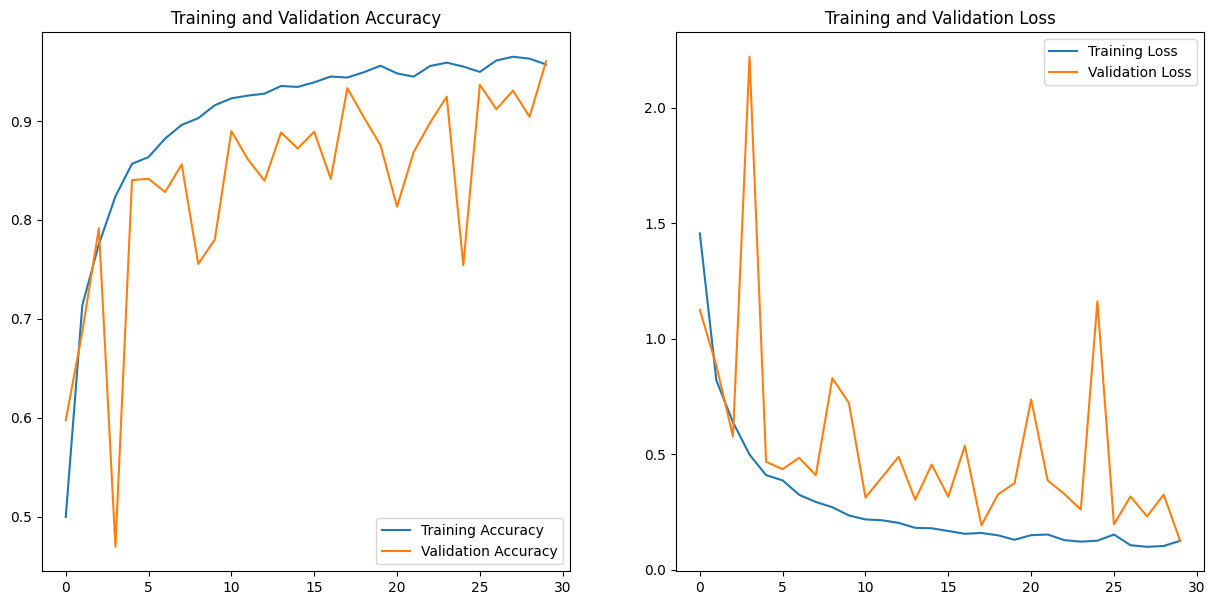

In [22]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

### Save the model

In [23]:
model.save('Model CNN.keras')